<a href="https://colab.research.google.com/github/SarahAbuirmeileh/PyTorch_Learning/blob/02-PyTorch-Neural-Network-Classification/02_PyTorch_Neural_Network_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# What is a classification problem?
A classification problem involves predicting whether something is one thing or another.

# Architecture of a classification neural network¶

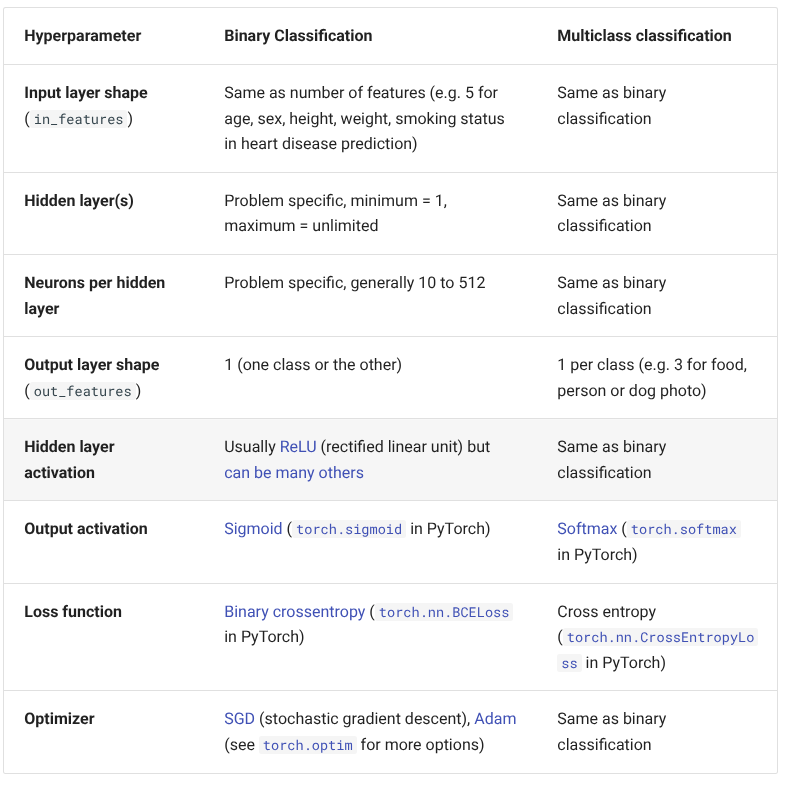

# Neural network classification with PyTorch

# 1. Make classification data and make it ready

In [1]:
import sklearn # for ML, like PyTorch for DL

from sklearn.datasets import make_circles

In [2]:
# make 1000 sample
n_samples = 1000

# create cirlces
# This create 1000 points and arranges them into two circles, one inside the other.
X, y = make_circles(n_samples=n_samples,
                    noise=0.03,
                    random_state=42)

In [3]:
len(X), len(y)

(1000, 1000)

In [4]:
# the X data contrinas of 2 featurs: the point corredint values (x, y)
# The y data is a binary classification, 0: belongs to the first circle, 1: to the second circle

print(f"Print first 5 samples of X:\n{X[:5]}")
print(f"Print first 5 samples of y:\n{y[:5]}")

Print first 5 samples of X:
[[ 0.75424625  0.23148074]
 [-0.75615888  0.15325888]
 [-0.81539193  0.17328203]
 [-0.39373073  0.69288277]
 [ 0.44220765 -0.89672343]]
Print first 5 samples of y:
[1 1 1 1 0]


In [5]:
import numpy as np

print(np.unique(y))


[0 1]



> This is a binary classification problem

In [6]:
## Make dataFrame of circle data

import pandas as pd # Excel spreadsheet library-like
circles = pd.DataFrame({
    "X1" : X[:, 0],
    "X2" : X[:, 1],
    "Lable": y
})

circles.head(10)

,X1,X2,Lable
0,0.754246,0.231481,1
1,-0.756159,0.153259,1
2,-0.815392,0.173282,1
3,-0.393731,0.692883,1
4,0.442208,-0.896723,0
5,-0.479646,0.676435,1
6,-0.013648,0.803349,1
7,0.771513,0.147760,1
8,-0.169322,-0.793456,1
9,-0.121486,1.021509,0


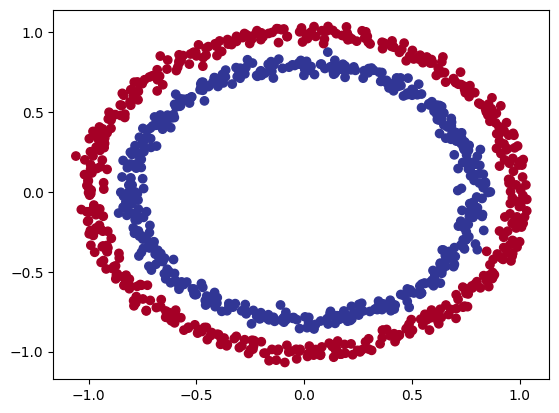

In [7]:
import matplotlib.pyplot as plt

plt.scatter(x=X[:, 0],
            y=X[:, 1],
            c=y,#color it with labels
            cmap=plt.cm.RdYlBu)

In [8]:
# Check data shape

X.shape, y.shape

((1000, 2), (1000,))

In [9]:
# View the first  example of features and labels

X_sample = X[0]
y_sample = y[0]

print(f"Sample of X: {X_sample}")
print(f"Sample of y: {y_sample}")

print(f"Shape of X: {X_sample.shape}")
print(f"Shape of y: {y_sample.shape}")

Sample of X: [0.75424625 0.23148074]
Sample of y: 1
Shape of X: (2,)
Shape of y: ()


### 1.2 Turn data into tensors and split train and test data


In [10]:
type(X)

numpy.ndarray

In [11]:
# turn data into tensors

import torch

X = torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.float)

X[:5], y[:5]

(tensor([[ 0.7542,  0.2315],
         [-0.7562,  0.1533],
         [-0.8154,  0.1733],
         [-0.3937,  0.6929],
         [ 0.4422, -0.8967]]),
 tensor([1., 1., 1., 1., 0.]))

In [12]:
# Splitting data into traning and testing
# The most common way to split data is to split randomly

from sklearn.model_selection import train_test_split

X_train_regrission, X_test, y_train_regrission, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42) # b. we use sklearn not pytorch

In [13]:
len(X_train_regrission), len(y_train_regrission), len(X_test), len(y_test)

(800, 800, 200, 200)

# Building a model

1. Set up device ognistic code
2. Create a model to classify out blue and red dots
3. create loss function and optimizer
4. create a traning and testing loop


In [14]:
# 1. Set up device ognistic code

device = "cuda" if torch.cuda.is_available() else "cpu"
print (device)
import torch.nn as nn


cuda


## 2. Create the model:
1. subclass nn.Module
2. Create 2 `nn.Linear()` layers to handel our data
3. Define a `forward()` method
4. instantioate an instance and send it to the target `device`

In [15]:
X_train_regrission.shape

torch.Size([800, 2])

In [16]:
# 1. subclass nn.Module
# in_features for the first layer = shape of the input
# out_features of hte last layer = shape of the output


class CircleModelV0(nn.Module):
  def __init__(self):
    super().__init__()

    # 2. create nn layers to handel out data -> See the size of the data (800, 2) we have 2 as input
    self.layer_1 = nn.Linear(in_features=2, out_features=5) # take 2 features and upscale them into 5 features
    self.layer_2 = nn.Linear(in_features=5, out_features=1)

  # 3. define the forward method
  def forward(self, x:torch.tensor)->torch.tensor:
    # x goes to the layer 1, then the results goes to the layer 2 and send the results
    # x -> layer_1 -> layer_2
    return self.layer_2(self.layer_1(x))

# 4.. instantiont an instance of our model and send it to the device

model_0 = CircleModelV0().to(device)
model_0

CircleModelV0(
  (layer_1): Linear(in_features=2, out_features=5, bias=True)
  (layer_2): Linear(in_features=5, out_features=1, bias=True)
)

In [17]:
next(model_0.parameters()).device

device(type='cuda', index=0)

# Visual Neural netweok representation:
https://playground.tensorflow.org/#activation=tanh&batchSize=10&dataset=circle&regDataset=reg-plane&learningRate=0.03&regularizationRate=0&noise=0&networkShape=4,2&seed=0.69054&showTestData=false&discretize=false&percTrainData=50&x=true&y=true&xTimesY=false&xSquared=false&ySquared=false&cosX=false&sinX=false&cosY=false&sinY=false&collectStats=false&problem=classification&initZero=false&hideText=false

# Simpler way to create a nn without class

In [18]:
model_1 = nn.Sequential(
    nn.Linear(in_features=2, out_features=5),
    nn.Linear(in_features=5, out_features=1)
)

# It will do the same as class, it do forward fun behid the sceen
# but when we have more complex op and comple forward fun, it is better to use the class

# Also when can write the class in this way:

class CircleModelV0_1(nn.Module):
  def __init__(self):
    super().__init__()

    self.two_linear_layers = nn.Sequential(
        nn.Linear(in_features=2, out_features=5),
        nn.Linear(in_features=5, out_features=1)
    )

  def forward(self, x:torch.tensor)->torch.tensor:

    return self.two_linear_layers(x)


In [19]:
print(model_0.state_dict())

# layer 1:
# 5 values for bias, b. we have 5 out_features
# we have 2*5 valeus in the weight, b. we have 2 in features, and 5 out ones

# layer 2:
# one value for bias, b. we have 1 out_featuers
# 5 values in wight, b, 5*1 (out  ) in featus

OrderedDict({'layer_1.weight': tensor([[-0.1497, -0.0730],
        [-0.0932,  0.6379],
        [-0.0535, -0.3272],
        [ 0.6381,  0.4622],
        [-0.0966, -0.5565]], device='cuda:0'), 'layer_1.bias': tensor([ 0.5121, -0.4187, -0.5837,  0.5013,  0.0418], device='cuda:0'), 'layer_2.weight': tensor([[ 0.1963, -0.2130, -0.3742,  0.0629,  0.3367]], device='cuda:0'), 'layer_2.bias': tensor([0.3689], device='cuda:0')})


In [20]:
# Make some predictions
model_0.eval()
with torch.inference_mode():
  untrained_preds = model_0(X_test.to(device))
print(f" first 10 preds: \n{untrained_preds[:10]}")
print(f" first 10 labels: \n{y_test[:10]}")

 first 10 preds: 
tensor([[0.6887],
        [0.6442],
        [0.8684],
        [0.6376],
        [0.9682],
        [0.9403],
        [0.7358],
        [0.8054],
        [0.8639],
        [0.6423]], device='cuda:0')
 first 10 labels: 
tensor([1., 0., 1., 0., 1., 1., 0., 0., 1., 0.])


In [21]:
# make round() to make the preds look similer to output

print(torch.round(untrained_preds[:10]))

tensor([[1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.]], device='cuda:0')


### 2.1 Setup loss function and optmizer

which opt and loss fun to use
-> **problem scpicifc**

e.g., for regrsion -> you might use: MSE / MAE -> mean squear/absolute error

for classification : binary cross entropy / categorical cross entropy


**for oprimizer:**

SGD and Adam are common, however there are many built in options in pytorch


For the loss function we're going to use `torch.nn.BCEWithLogitsLoss()`, for more on what binary cross entropy (BCE) is, check out this article - https://towardsdatascience.com/understanding-binary-cross-entropy-log-loss-a-visual-explanation-a3ac6025181a
For a defintion on what a logit is in deep learning - https://stackoverflow.com/a/52111173/7900723
For different optimizers see torch.optim

In [22]:
# Set up loss fun

loss_fn = nn.BCEWithLogitsLoss() # has segmoid activation fun built in
# More stable than the next one

# if we used nn.BCELoss() the input have to go through sigmoind activation fun befre, so we have to do this :

# nn.Sequential(
#   nn.Sigmoid(),
#   nn.BCELoss()
# )

In [23]:
# Set up optmizer
optimizer = torch.optim.SGD(params=model_0.parameters(),
                            lr=0.1)

In [24]:
model_0.state_dict()

OrderedDict([('layer_1.weight',
              tensor([[-0.1497, -0.0730],
                      [-0.0932,  0.6379],
                      [-0.0535, -0.3272],
                      [ 0.6381,  0.4622],
                      [-0.0966, -0.5565]], device='cuda:0')),
             ('layer_1.bias',
              tensor([ 0.5121, -0.4187, -0.5837,  0.5013,  0.0418], device='cuda:0')),
             ('layer_2.weight',
              tensor([[ 0.1963, -0.2130, -0.3742,  0.0629,  0.3367]], device='cuda:0')),
             ('layer_2.bias', tensor([0.3689], device='cuda:0'))])

In [25]:
# Calcualte the accurecy - the prescentage that our model got right
def accuracy_fn(y_true, y_preds):
  correct = torch.eq(y_true, y_preds).sum()
  accuracy = correct/len(y_preds) * 100
  return accuracy

In [26]:
# 3. Train the model

# 3.1 going from raw logits -> prediction probability -> predection lables
**logits**: are the raw scores a model produces before converting them into probabilities.

are just numbers. e.g., [2, 1]

after converting them, [0.73, 0.44]


The output of our model is logits, we cen convert the, by passing them into an ctivetion function (e.g., **sigmod** for binary cross entropy, and **softmax** for multiclass classification)

after that we can turn the prediciotn problalibtis into into **prediction lables** by either round them or taking the `argmax()`

In [27]:
# View the first 5 outputs of the forward pass on the test data
model_0.eval()
with torch.inference_mode():
  y_logits = model_0(X_test.to(device))
y_logits[:5]

tensor([[0.6887],
        [0.6442],
        [0.8684],
        [0.6376],
        [0.9682]], device='cuda:0')

In [28]:
y_test[:5]

tensor([1., 0., 1., 0., 1.])

In [29]:
# Use the sigmod activation funtion on our model logits to turn them into prediction problaiblities
y_pred_probs = torch.sigmoid(y_logits)
y_pred_probs[:5]

tensor([[0.6657],
        [0.6557],
        [0.7044],
        [0.6542],
        [0.7248]], device='cuda:0')

In [30]:
torch.round(y_pred_probs[:5])

tensor([[1.],
        [1.],
        [1.],
        [1.],
        [1.]], device='cuda:0')

For our prediction probability values, we need to perform a range-style rounding on them:

`y_pred_probs` >= 0.5, `y=1` (class 1)

`y_pred_probs` < 0.5, `y=0` (class 0)


In [31]:
# Find the prediction lables
y_preds = torch.round(y_pred_probs)

# In full
y_pred_lables = torch.round(torch.sigmoid(model_0(X_test.to(device))))[:5]

# Check equality
# print(torch.eq(y_test.to(device)[:5], y_pred_lables))

# We have to get tide of extra dimetion
print(torch.eq(y_test.to(device).squeeze()[:5], y_pred_lables.squeeze()))

tensor([ True, False,  True, False,  True], device='cuda:0')


# 3.2 Build a trainign and tesing loop

In [32]:
MANUAL_SEED = 42
torch.manual_seed(MANUAL_SEED)
torch.cuda.manual_seed(MANUAL_SEED)

X_train_regrission, y_train_regrission = X_train_regrission.to(device), y_train_regrission.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

epochs = 100


for epoch in range(epochs):
  model_0.train()

  # 1. forward pass
  y_logits = model_0(X_train_regrission).squeeze()
  y_pred = torch.round(torch.sigmoid(y_logits))

  # 2. calcualte loss/accuracy
  # nn.BCEWithLogitsLoss() -> Expect logits
  loss = loss_fn(y_logits, y_train_regrission)
  accuracy = accuracy_fn(y_true=y_train_regrission, y_preds=y_pred)

  # nn.BCELoss() -> without logits
  # if we use  nn.BCELoss()
  # loss = loss_fn(torch.sigmoid(y_logits), y_train)

  # 3. optimizer zero grad
  optimizer.zero_grad()

  # 4.loss backward
  loss.backward()

  # 5. optimizer step (graident descent)
  optimizer.step()


  # Testing
  model_0.eval()
  with torch.inference_mode():
    #1. forward pass
    test_logits = model_0(X_test).squeeze()
    test_pred = torch.round(torch.sigmoid(test_logits))

    # 2. calcualte test loss/accuracy
    test_loss = loss_fn(test_logits, y_test)
    test_accuracy = accuracy_fn(y_true=y_test, y_preds=test_pred)

  # Print what is happening
  if epoch % 10 == 0:
    print(f"Epoch: {epoch} | Loss: {loss:.5f} | Accuracy: {accuracy:.2f}% | Test Loss: {test_loss:.5f} | Test Accuracy: {test_accuracy:.2f}%")

Epoch: 0 | Loss: 0.77852 | Accuracy: 50.00% | Test Loss: 0.76235 | Test Accuracy: 50.00%
Epoch: 10 | Loss: 0.72370 | Accuracy: 50.00% | Test Loss: 0.71465 | Test Accuracy: 50.00%
Epoch: 20 | Loss: 0.70543 | Accuracy: 50.00% | Test Loss: 0.69913 | Test Accuracy: 50.00%
Epoch: 30 | Loss: 0.69880 | Accuracy: 50.00% | Test Loss: 0.69388 | Test Accuracy: 50.00%
Epoch: 40 | Loss: 0.69617 | Accuracy: 58.75% | Test Loss: 0.69214 | Test Accuracy: 57.50%
Epoch: 50 | Loss: 0.69500 | Accuracy: 53.62% | Test Loss: 0.69165 | Test Accuracy: 54.50%
Epoch: 60 | Loss: 0.69439 | Accuracy: 51.88% | Test Loss: 0.69161 | Test Accuracy: 54.50%
Epoch: 70 | Loss: 0.69402 | Accuracy: 51.38% | Test Loss: 0.69174 | Test Accuracy: 53.50%
Epoch: 80 | Loss: 0.69377 | Accuracy: 50.87% | Test Loss: 0.69193 | Test Accuracy: 54.50%
Epoch: 90 | Loss: 0.69359 | Accuracy: 50.12% | Test Loss: 0.69215 | Test Accuracy: 53.00%


# 4. make a prediction  and evaluate the model, to know why it is's learning
From the matrix it looks like out model is not learning anything

so let's make some predictions and make them visual

to do so, we need to import function called `plot_decision_boundary()`

In [33]:
import requests
from pathlib import Path

# Donwload helper function from Learn PyTorch repo (send a reqest to them and get the function from the repo - if it is not downloaded)

if Path("helper_functions.py").is_file():
  print("helper_functions.py already exists, skipped downloading")
else:
  print("Downloading helper helper_functions.py")
  # The url must be in the raw formate -> just click raw on the github file
  request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/refs/heads/main/helper_functions.py")

  # create the helper_functions file and write the content of th req in it
  with open("helper_functions.py", "wb") as f: # as file
    f.write(request.content)

from helper_functions import plot_predictions, plot_decision_boundary

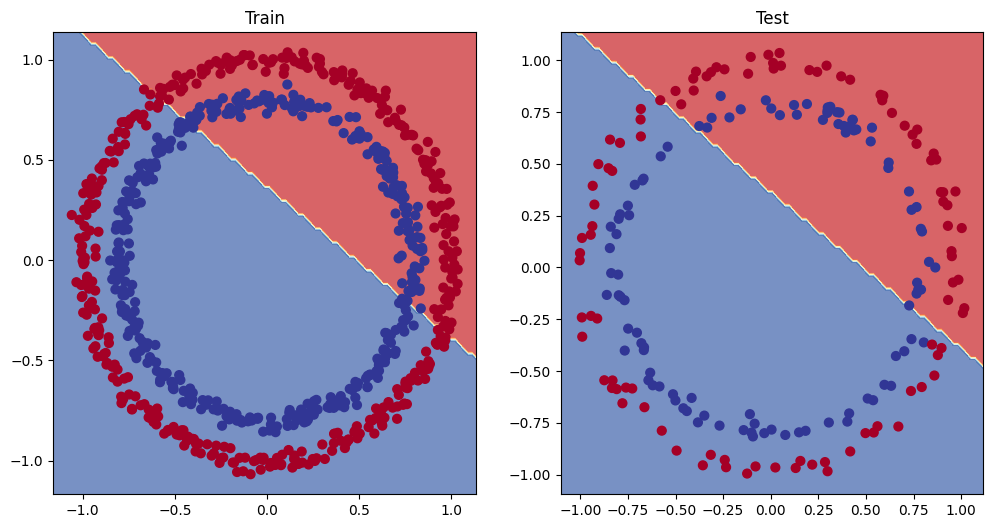

In [34]:
# Plot decision boundary of the model

import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_0, X_train_regrission, y_train_regrission)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_0, X_test, y_test)

# Why our model predictions are not good?

we are trying to sperate cirlce in straight lines -> won't succesed


The linerity came from the laers we used `nn.Liner()`

## 5. Improving out model (from a model perspcitve)

* Add more layers -> give the mmodel the chance to learn about patterns in the sata
* Add more hidden units - go from 5 hidden units into 10 -> more parameters the model have to represnt the data
* Fit for longer
* Changing the activation function
* Change the learning rate
* Change the loss function


These options are all fomr a model perscpictive, b. they deal directly with the model, rather than the data

B. these options are all values we (as ML and data scientes) can change, they are called **hyperparameters**

## Let's try to imporve pur model

** We do 1 change at a time and see the results -> Experimnet tracking**

* Add more hidden units: 5 -> 10
* increase teh number of layers: 2 -> 3
* incresea the number of epochs: 100 -> 1000

In [35]:
class CircleModelV1(nn.Module):
  def __init__(self):
    super().__init__()

    self.layer_1 = nn.Linear(in_features=2, out_features=10)
    self.layer_2 = nn.Linear(in_features=10, out_features=10)
    self.layer_3 = nn.Linear(in_features=10, out_features=1)

  def forward(self, x):
    # z = self.layer_1(x)
    # z = self.layer_2(z)
    # z = self.layer_3(z)
    return self.layer_3(self.layer_2(self.layer_1(x))) # this way of writing operations leverages speed ups where possible behind the scenes

model_1 = CircleModelV1().to(device)

In [36]:
# Create a loss fun
loss_fn = nn.BCEWithLogitsLoss()

# Create an optmizer
optimizer  = torch.optim.SGD(params=model_1.parameters(),
                                lr=0.1)


In [37]:
# Write traning and evaaution loop

MANUAL_SEED = 42
torch.manual_seed(MANUAL_SEED)
torch.cuda.manual_seed(MANUAL_SEED)

# Put the data in the right device
X_train_regrission, y_train_regrission = X_train_regrission.to(device), y_train_regrission.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

# Trian for longer
epochs = 1000
for epoch in range(epochs):
  model_1.train()

  y_logits = model_1(X_train_regrission).squeeze()
  y_preds = torch.round(torch.sigmoid(y_logits))

  # Calc the loss
  loss = loss_fn(y_logits, y_train_regrission)
  accuracy = accuracy_fn(y_true=y_train_regrission, y_preds=y_preds)

  optimizer.zero_grad()

  loss.backward()

  optimizer.step()

  # Evaluation
  model_1.eval()
  with torch.inference_mode():
    test_logits = model_1(X_test).squeeze()
    test_preds = torch.round(torch.sigmoid(test_logits))

    test_loss = loss_fn(test_logits, y_test)
    test_accuracy = accuracy_fn(y_true=y_test, y_preds=test_preds)

    if epoch % 100 == 0:
      print(f"Epoch: {epoch} | Loss: {loss:.5f} | Accuracy: {accuracy:.2f}% | Test Loss: {test_loss:.5f} | Test Accuracy: {test_accuracy:.2f}%")


Epoch: 0 | Loss: 0.69396 | Accuracy: 50.87% | Test Loss: 0.69261 | Test Accuracy: 51.00%
Epoch: 100 | Loss: 0.69305 | Accuracy: 50.37% | Test Loss: 0.69379 | Test Accuracy: 48.00%
Epoch: 200 | Loss: 0.69299 | Accuracy: 51.12% | Test Loss: 0.69437 | Test Accuracy: 46.00%
Epoch: 300 | Loss: 0.69298 | Accuracy: 51.62% | Test Loss: 0.69458 | Test Accuracy: 45.00%
Epoch: 400 | Loss: 0.69298 | Accuracy: 51.12% | Test Loss: 0.69465 | Test Accuracy: 46.00%
Epoch: 500 | Loss: 0.69298 | Accuracy: 51.00% | Test Loss: 0.69467 | Test Accuracy: 46.00%
Epoch: 600 | Loss: 0.69298 | Accuracy: 51.00% | Test Loss: 0.69468 | Test Accuracy: 46.00%
Epoch: 700 | Loss: 0.69298 | Accuracy: 51.00% | Test Loss: 0.69468 | Test Accuracy: 46.00%
Epoch: 800 | Loss: 0.69298 | Accuracy: 51.00% | Test Loss: 0.69468 | Test Accuracy: 46.00%
Epoch: 900 | Loss: 0.69298 | Accuracy: 51.00% | Test Loss: 0.69468 | Test Accuracy: 46.00%


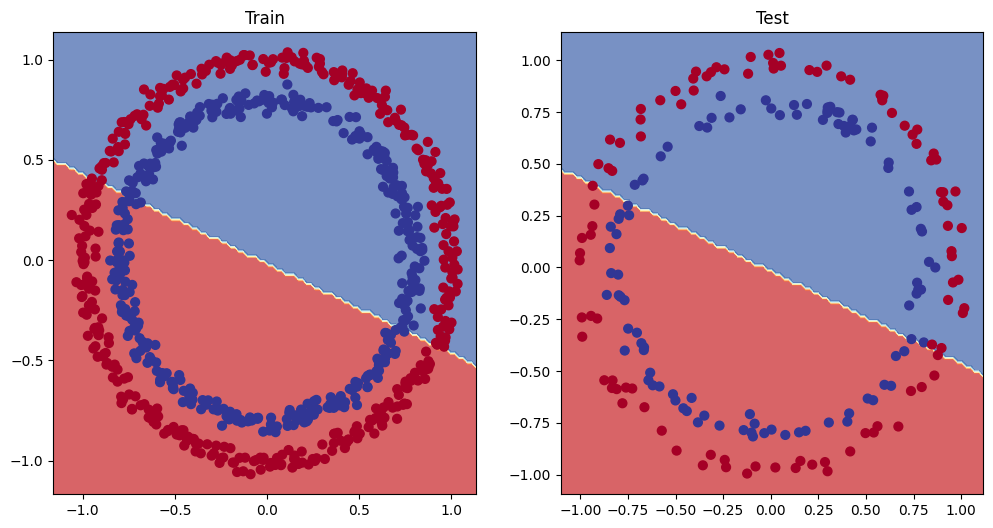

In [38]:
# Plot the decision boundary
plt.figure(figsize=(12,6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_1, X_train_regrission, y_train_regrission)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_1, X_test, y_test)

# Preparing our data to see if our model can fit a straight line

One way to truobleshoot a larg probel is to test out a smaller problem

In [39]:
# Create some data (same as notebook 01)
weight = 0.7
bias = 0.3
start = 0
end = 1
step = 0.01

# Create data
X_regression = torch.arange(start, end, step).unsqueeze(dim=1)
y_regression = weight * X_regression + bias # Linear regression formula (without epsilon)

# Check the data
print(len(X_regression))
X_regression[:5], y_regression[:5]

100


(tensor([[0.0000],
         [0.0100],
         [0.0200],
         [0.0300],
         [0.0400]]),
 tensor([[0.3000],
         [0.3070],
         [0.3140],
         [0.3210],
         [0.3280]]))

In [40]:

# Create train and test splits
train_split = int(0.8 * len(X_regression))
X_train_regression, y_train_regression = X_regression[:train_split], y_regression[:train_split]
X_test_regression, y_test_regression = X_regression[train_split:], y_regression[train_split:]

# Check the lengths of each
len(X_train_regression), len(X_test_regression), len(y_train_regression), len(y_test_regression)


(80, 20, 80, 20)

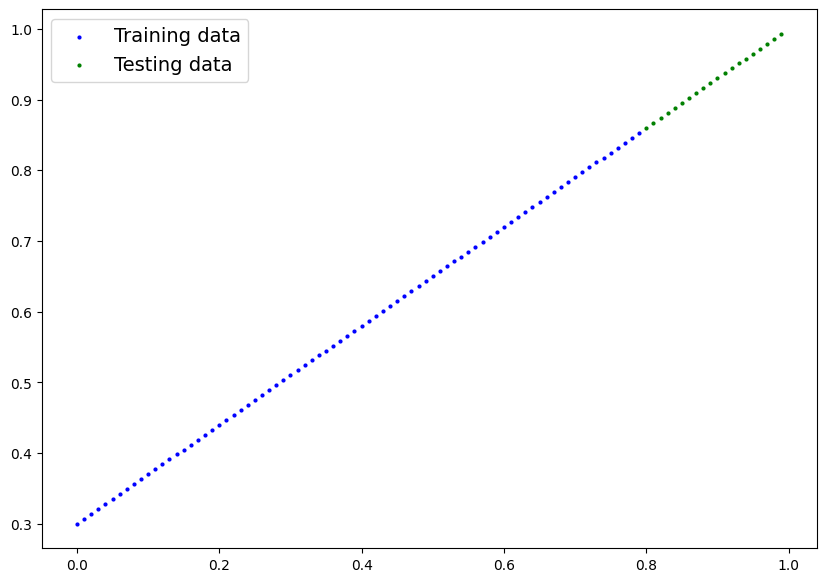

In [41]:
plot_predictions(train_data=X_train_regression,
                 train_labels=y_train_regression,
                 test_data=X_test_regression,
                 test_labels=y_test_regression);

## Adjust model_1 to fit a stratght line  

In [42]:
# Same architiure as model_1 (but using nn.Sequential())
# and the number of in_features is 1 now

model_2 = nn.Sequential(
    nn.Linear(in_features=1, out_features=10),
    nn.Linear(in_features=10, out_features=10),
    nn.Linear(in_features=10, out_features=1)
).to(device)

In [43]:
# Loss and optmizer

loss_fn = nn.L1Loss()
optmizer = torch.optim.SGD(params=model_2.parameters(),
                        lr=0.01)

In [44]:
# Train the model

RANDOM_SEED = 42
torch.manual_seed(RANDOM_SEED)
torch.cuda.manual_seed(RANDOM_SEED)

epochs = 1000

for epoch in range(epochs):
  model_2.train()

  # Put the data into the device
  X_train_regression, y_train_regression = X_train_regression.to(device), y_train_regression.to(device)

  X_test_regression, y_test_regression = X_test_regression.to(device), y_test_regression.to(device)

  # 1. forward pass
  y_preds = model_2(X_train_regression).squeeze()
  loss = loss_fn(y_preds, y_test_regression)

  optimizer.zero_grad()

  loss.backward()

  optimizer.step()

  model_2.eval()
  with torch.inference_mode():
    test_preds = model_2(X_test_regression).squeeze()
    test_loss = loss_fn(test_preds, y_test_regression)

  if epoch % 100 == 0:
    print(f"Epoch: {epoch} | Loss: {loss:.5f} | Test Loss: {test_loss:.5f}")

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/loss.py:129: UserWarning: Using a target size (torch.Size([20, 1])) that is different to the input size (torch.Size([80])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.l1_loss(input, target, reduction=self.reduction)
/usr/local/lib/python3.13/dist-packages/torch/nn/modules/loss.py:129: UserWarning: Using a target size (torch.Size([20, 1])) that is different to the input size (torch.Size([20])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.l1_loss(input, target, reduction=self.reduction)


Epoch: 0 | Loss: 1.10986 | Test Loss: 0.95396
Epoch: 100 | Loss: 1.10986 | Test Loss: 0.95396
Epoch: 200 | Loss: 1.10986 | Test Loss: 0.95396
Epoch: 300 | Loss: 1.10986 | Test Loss: 0.95396
Epoch: 400 | Loss: 1.10986 | Test Loss: 0.95396
Epoch: 500 | Loss: 1.10986 | Test Loss: 0.95396
Epoch: 600 | Loss: 1.10986 | Test Loss: 0.95396
Epoch: 700 | Loss: 1.10986 | Test Loss: 0.95396
Epoch: 800 | Loss: 1.10986 | Test Loss: 0.95396
Epoch: 900 | Loss: 1.10986 | Test Loss: 0.95396


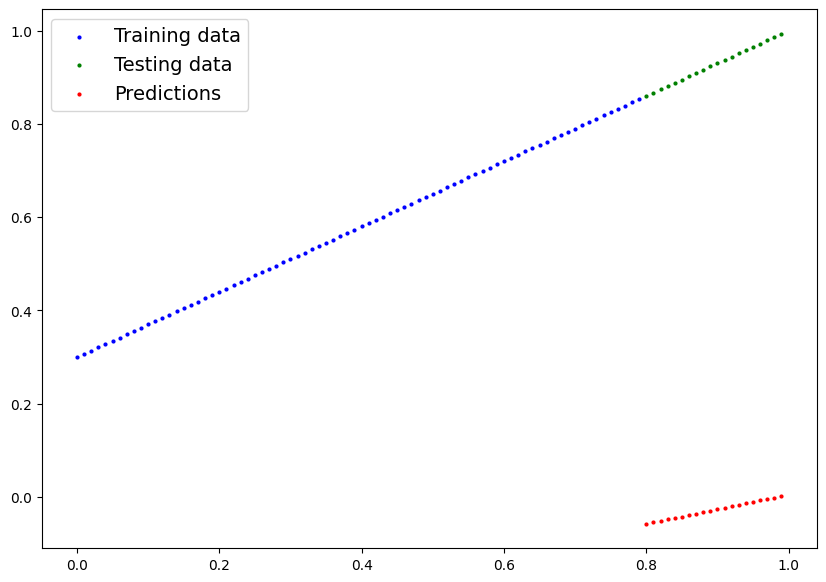

In [45]:
# Turn on evel mode

model_2.eval()
with torch.inference_mode():
  y_preds = model_2(X_test_regression).squeeze()

plot_predictions(train_data=X_train_regression.cpu(),
                 train_labels=y_train_regression.cpu(),
                 test_data=X_test_regression.cpu(),
                 test_labels=y_test_regression.cpu(),
                 predictions=y_preds.cpu())


### We need non-linearity to fit our data

## 6. The missing piece of our model: non-linearity

" what patterns can you draw if you were given an infinit amount of a srtaight and non-striaght lines ?"


Or in ML terms, an infinte (but really it's finite) of linear and non-linear functions?


**The whole idea is to combine the power of linear and non-linear function**

### 6.1 Recreating non-linear data (red and blue cirles)




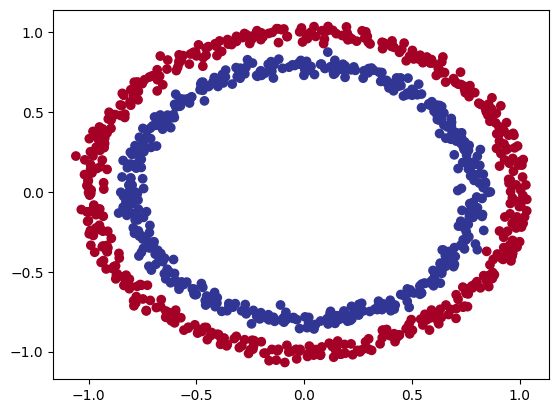

In [46]:
# Make and plot data

import matplotlib.pyplot as plt
from sklearn.datasets import make_circles

n_samples = 1000

x, y = make_circles(n_samples=n_samples,
                    noise=0.03,
                    random_state=42)

plt.scatter(X[:,0], X[:, 1], c=y, cmap=plt.cm.RdYlBu)

In [47]:
# Convert data into tesnors, then split it into train and test
import torch
from sklearn.model_selection import train_test_split

X, y = torch.from_numpy(x).type(torch.float), torch.from_numpy(y).type(torch.float)

# split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train[:5], y_train[:5]

(tensor([[ 0.6579, -0.4651],
         [ 0.6319, -0.7347],
         [-1.0086, -0.1240],
         [-0.9666, -0.2256],
         [-0.1666,  0.7994]]),
 tensor([1., 0., 0., 0., 1.]))

### 6.2: building a model with non-linearity

nn.s: are a larg combination of linear and non-linear functions which are potaionely identfy patterns in data


In [48]:
 # Build a model with non-linear activation functions
from torch import nn

class CircleModelV2(nn.Module):
  def __init__(self):
    super().__init__()

    self.layer1 = nn.Linear(in_features=2, out_features=10)
    self.layer2 = nn.Linear(in_features=10, out_features=10)
    self.layer3 = nn.Linear(in_features=10, out_features=1)
    # non-linear fun
    self.relu = nn.ReLU()

  def forward(self, x):
    # We should put the non-linear fun between each layer
    return self.layer3(self.relu(self.layer2(self.relu(self.layer1(x)))))

model_3 = CircleModelV2().to(device)
model_3

CircleModelV2(
  (layer1): Linear(in_features=2, out_features=10, bias=True)
  (layer2): Linear(in_features=10, out_features=10, bias=True)
  (layer3): Linear(in_features=10, out_features=1, bias=True)
  (relu): ReLU()
)

In [49]:
# Set up loss fun and optmizer

loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(params=model_3.parameters(),
                            lr=0.1)

### 6.3 Train the model with non-linearity

In [50]:
# random seed

RANDOM_SEED = 42
torch.manual_seed(RANDOM_SEED)
torch.cuda.manual_seed(RANDOM_SEED)

# Send the data to the devicce
X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

# Loop through data
epochs = 1000

for epoch in range(epochs):
  model_3.train()

  y_logits = model_3(X_train).squeeze()
  y_preds = torch.round(torch.sigmoid(y_logits))

  loss = loss_fn(y_logits, y_train)
  accuracy = accuracy_fn(y_true=y_train, y_preds=y_preds)

  optimizer.zero_grad()

  loss.backward()

  optimizer.step()

  #
  model_3.eval()
  with torch.inference_mode():
    test_logits = model_3(X_test).squeeze()
    test_preds = torch.round(torch.sigmoid(test_logits))

    test_loss = loss_fn(test_logits, y_test)
    test_accuracy = accuracy_fn(y_true=y_test, y_preds=test_preds)

    if epoch % 100 == 0:
      print(f"Epoch: {epoch} | Loss: {loss:.5f} | Accuracy: {accuracy:.2f}% | Test Loss: {test_loss:.5f} | Test Accuracy: {test_accuracy:.2f}%")

Epoch: 0 | Loss: 0.69295 | Accuracy: 50.00% | Test Loss: 0.69319 | Test Accuracy: 50.00%
Epoch: 100 | Loss: 0.69115 | Accuracy: 52.88% | Test Loss: 0.69102 | Test Accuracy: 52.50%
Epoch: 200 | Loss: 0.68977 | Accuracy: 53.38% | Test Loss: 0.68940 | Test Accuracy: 55.00%
Epoch: 300 | Loss: 0.68795 | Accuracy: 53.00% | Test Loss: 0.68723 | Test Accuracy: 56.00%
Epoch: 400 | Loss: 0.68517 | Accuracy: 52.75% | Test Loss: 0.68411 | Test Accuracy: 56.50%
Epoch: 500 | Loss: 0.68102 | Accuracy: 52.75% | Test Loss: 0.67941 | Test Accuracy: 56.50%
Epoch: 600 | Loss: 0.67515 | Accuracy: 54.50% | Test Loss: 0.67285 | Test Accuracy: 56.00%
Epoch: 700 | Loss: 0.66659 | Accuracy: 58.38% | Test Loss: 0.66322 | Test Accuracy: 59.00%
Epoch: 800 | Loss: 0.65160 | Accuracy: 64.00% | Test Loss: 0.64757 | Test Accuracy: 67.50%
Epoch: 900 | Loss: 0.62362 | Accuracy: 74.00% | Test Loss: 0.62145 | Test Accuracy: 79.00%


### 6.4 evaluation a model trained with non-linear activation functions

In [51]:
# Make a prediction:

model_3.eval()
with torch.inference_mode():
  y_logits = model_3(X_test).squeeze()
  y_preds = torch.round(torch.sigmoid(y_logits)).squeeze()

y_preds[:10], y_test[:10]

(tensor([1., 0., 1., 0., 0., 1., 0., 0., 1., 0.], device='cuda:0'),
 tensor([1., 0., 1., 0., 1., 1., 0., 0., 1., 0.], device='cuda:0'))

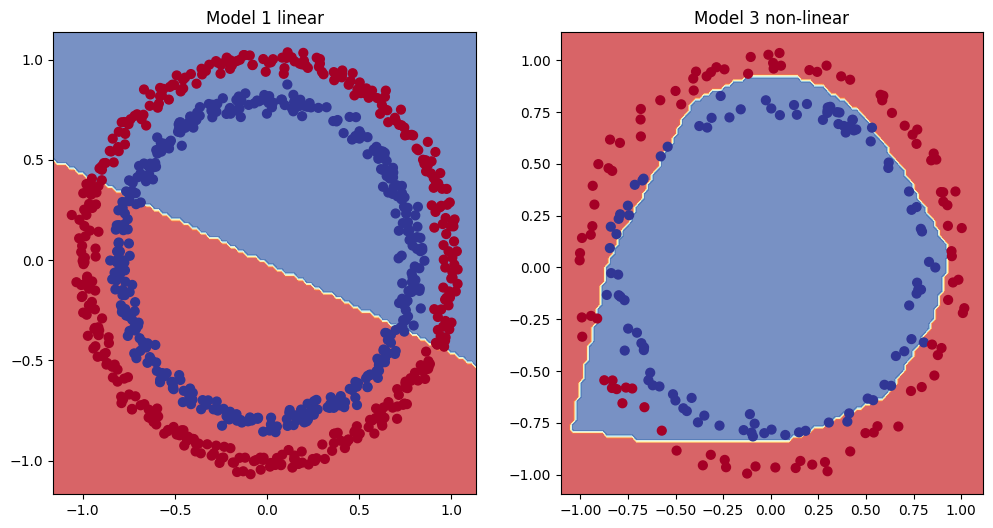

In [52]:
# plot decision boundary
plt.figure(figsize=(12,6))
plt.subplot(1, 2, 1)
plt.title("Model 1 linear")
plot_decision_boundary(model_1, X_train, y_train)
plt.subplot(1, 2, 2)
plt.title("Model 3 non-linear")
plot_decision_boundary(model_3, X_test, y_test)

# 7. replicating non-linear activation functions

Nural network, rather us tell the model what to learn, we give it the ools to discover the patterns in data and it tries to figure out the best patterns in it's own

These tools are: linear and non-linear functions

In [53]:
# Create a tensor

A = torch.arange(-10, 10, 1, dtype=torch.float32)
A.dtype

torch.float32

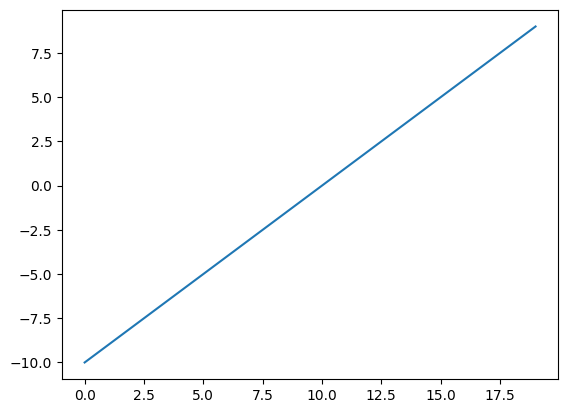

In [54]:
# Visulzae the data

plt.plot(A)

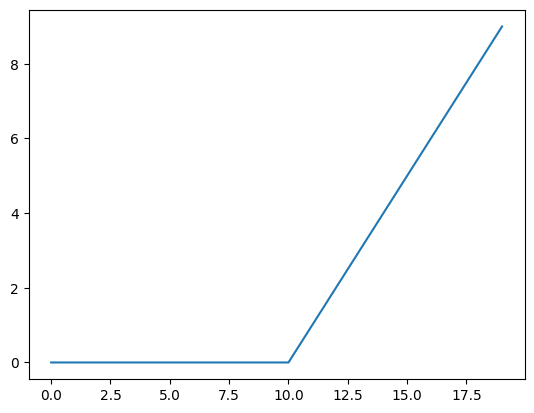

In [55]:
plt.plot(torch.relu(A))

In [56]:
def relu(x:torch.tensor)->torch.tensor:
  return torch.maximum(torch.tensor(0), x)
relu(A)

tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 2., 3., 4., 5., 6., 7.,
        8., 9.])

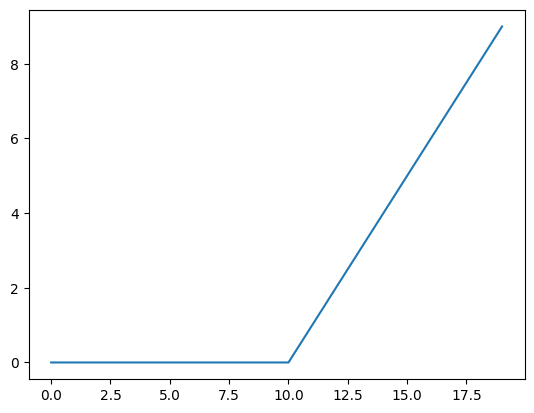

In [57]:
plt.plot(relu(A))

In [58]:
# now let's do the same for sigmoid

def sigmoid(x):
  return 1 / (1 + torch.exp(-x))

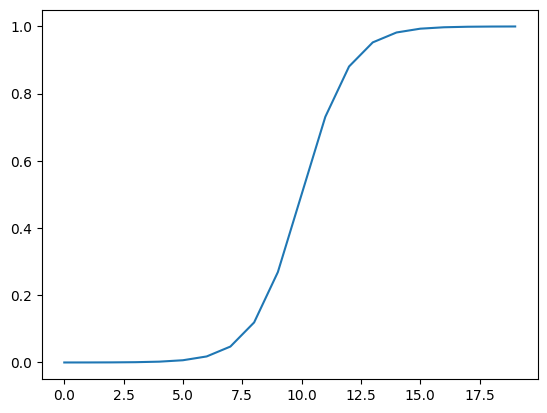

In [59]:
plt.plot(sigmoid(A))

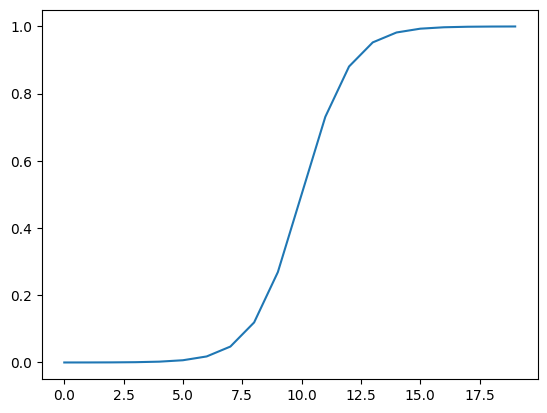

In [60]:
 plt.plot(torch.sigmoid(A))

## 8. Putting all together with a multiclass classification problem

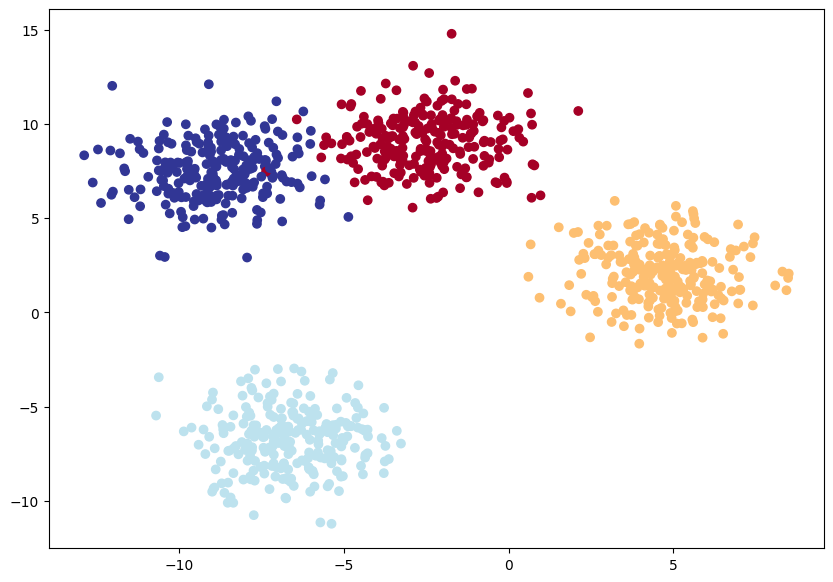

In [61]:
### 8.1   Creating a toy multi-class dataset

import torch
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

n_samples = 1000
NUM_CLASSES = 4
NUM_FEATURES = 2
RANDOM_SEED = 42

# 1. Create multi-class data
X_blob, y_blob = make_blobs(n_samples=n_samples,
                                        n_features=NUM_FEATURES,
                                        centers=NUM_CLASSES,
                                        cluster_std=1.5, # how spread out the data points are around the center of each class (cluster).
                                        random_state=RANDOM_SEED)

# 2. turn data into tensors
X_blob = torch.from_numpy(X_blob).type(torch.float)
y_blob = torch.from_numpy(y_blob).type(torch.LongTensor)

# 3. split data
from sklearn.model_selection import train_test_split

X_blob_train, X_blob_test, y_blob_train, y_blob_test = train_test_split(X_blob, y_blob, test_size=0.2, random_state=RANDOM_SEED)

# 4. plot the data
plt.figure(figsize=(10, 7))
plt.scatter(X_blob[:, 0], X_blob[:, 1], c=y_blob, cmap=plt.cm.RdYlBu)

### 8.2 Building a multi-class classification model

In [62]:
# Create device agnostic code

device = "cuda" if torch.cuda.is_available() else "cpu"
device


'cuda'

In [63]:
 # build a multi-class classification model

class BlobModel(nn.Module):
  def __init__(self, in_features, out_features, hidden_units=8):
    """Initializes multi-class classification model.

    Args:
      in_features (int): Number of input features to the model
      out_features (int): Number of outputs features (number of output classes)
      hidden_units (int): Number of hidden units between layers, default 8

    Returns:

    Example:
    """
    super().__init__()
    self.linear_layer_stack = nn.Sequential(
        nn.Linear(in_features=in_features, out_features=hidden_units),
        nn.ReLU(),
        nn.Linear(in_features=hidden_units, out_features=hidden_units),
        nn.ReLU(),
        nn.Linear(in_features=hidden_units, out_features=out_features)
        )
  def forward(self, x):
    return self.linear_layer_stack(x)

# when we created the data, we defined the # of features
model_4 = BlobModel(in_features=2, out_features=4).to(device)
model_4

BlobModel(
  (linear_layer_stack): Sequential(
    (0): Linear(in_features=2, out_features=8, bias=True)
    (1): ReLU()
    (2): Linear(in_features=8, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=4, bias=True)
  )
)

In [64]:
X_blob_train.shape, y_blob_train.shape, y_blob_train[:5]

(torch.Size([800, 2]), torch.Size([800]), tensor([1, 0, 2, 2, 0]))

In [65]:
  # Create a loss fun and optimizer

loss_fn = nn.CrossEntropyLoss() # we can weight parameter, when we have unbalanced training sets
optimizer = torch.optim.SGD(params=model_4.parameters(),
                              lr=0.1)

In [66]:
# Getting a prediction probablites for a multi-class classification

model_4.eval()
with torch.inference_mode():
  y_logits = model_4(X_blob_test.to(device))
  y_pred_probs = torch.softmax(y_logits, dim=1)

y_logits[:10], y_pred_probs[:10]

(tensor([[-0.7646, -0.7412, -1.5777, -1.1376],
         [-0.0973, -0.9431, -0.5963, -0.1371],
         [ 0.2528, -0.2379,  0.1882, -0.0066],
         [-0.4134, -0.5204, -0.9303, -0.6963],
         [-0.3118, -1.3736, -1.1991, -0.3834],
         [-0.1497, -1.0617, -0.7107, -0.1645],
         [ 0.1539, -0.2887,  0.1520, -0.0109],
         [-0.2154, -1.1795, -0.9300, -0.2745],
         [ 0.2443, -0.2472,  0.1649,  0.0061],
         [-0.2329, -1.2120, -0.9849, -0.3004]], device='cuda:0'),
 tensor([[0.3169, 0.3244, 0.1405, 0.2182],
         [0.3336, 0.1432, 0.2026, 0.3206],
         [0.3011, 0.1843, 0.2823, 0.2323],
         [0.3078, 0.2766, 0.1836, 0.2320],
         [0.3719, 0.1286, 0.1532, 0.3463],
         [0.3381, 0.1358, 0.1929, 0.3331],
         [0.2867, 0.1841, 0.2861, 0.2431],
         [0.3554, 0.1355, 0.1740, 0.3351],
         [0.3009, 0.1841, 0.2779, 0.2371],
         [0.3595, 0.1350, 0.1695, 0.3360]], device='cuda:0'))

In [67]:
y_pred_probs[0].sum()
# This is a probabilty for each class -> sum = 1

# max arg, give the class name for the highest prob

tensor(1., device='cuda:0')

In [68]:
# convert our model's prediction probabilities to prediction labels
y_pred_labels = torch.argmax(y_pred_probs, dim=1)
# dim=1 because we want to find the highest probability among classes for each sample
y_pred_labels[:10]

tensor([1, 0, 0, 0, 0, 0, 0, 0, 0, 0], device='cuda:0')

### 8.5 Creating a training loop and testing loop for a multi-class PyTorch model

In [69]:
torch.manual_seed(RANDOM_SEED)
torch.cuda.manual_seed(RANDOM_SEED)

epochs = 100
# put data into the device
X_blob_train, y_blob_train = X_blob_train.to(device), y_blob_train.to(device)
X_blob_test, y_blob_test = X_blob_test.to(device), y_blob_test.to(device)

for epoch in range(epochs):
  model_4.train()

  y_logits = model_4(X_blob_train)
  y_preds = torch.softmax(y_logits, dim=1).argmax(dim=1)

  loss = loss_fn(y_logits, y_blob_train)
  acc = accuracy_fn(y_true=y_blob_train, y_preds=y_preds)

  optimizer.zero_grad()
  loss.backward()

  optimizer.step()

  # Testing
  model_4.eval()
  with torch.inference_mode():
    test_logits = model_4(X_blob_test)
    test_preds = torch.softmax(test_logits, dim=1).argmax(dim=1)
    test_loss = loss_fn(test_logits, y_blob_test)
    test_acc = accuracy_fn(y_true=y_blob_test, y_preds=test_preds)

  if epoch % 10 == 0:
    print(f"Epoch: {epoch} | Loss: {loss:.5f} | Accuracy: {acc:.2f}% | Test Loss: {test_loss:.5f} | Test Accuracy: {test_acc:.2f}%")

Epoch: 0 | Loss: 1.15883 | Accuracy: 40.38% | Test Loss: 1.07554 | Test Accuracy: 48.00%
Epoch: 10 | Loss: 0.64476 | Accuracy: 96.75% | Test Loss: 0.66069 | Test Accuracy: 97.50%
Epoch: 20 | Loss: 0.42535 | Accuracy: 98.50% | Test Loss: 0.43074 | Test Accuracy: 100.00%
Epoch: 30 | Loss: 0.25294 | Accuracy: 99.12% | Test Loss: 0.24508 | Test Accuracy: 99.50%
Epoch: 40 | Loss: 0.11232 | Accuracy: 99.25% | Test Loss: 0.10229 | Test Accuracy: 99.50%
Epoch: 50 | Loss: 0.06627 | Accuracy: 99.25% | Test Loss: 0.05848 | Test Accuracy: 99.50%
Epoch: 60 | Loss: 0.05068 | Accuracy: 99.25% | Test Loss: 0.04293 | Test Accuracy: 99.50%
Epoch: 70 | Loss: 0.04300 | Accuracy: 99.25% | Test Loss: 0.03491 | Test Accuracy: 99.50%
Epoch: 80 | Loss: 0.03836 | Accuracy: 99.25% | Test Loss: 0.02988 | Test Accuracy: 99.50%
Epoch: 90 | Loss: 0.03525 | Accuracy: 99.25% | Test Loss: 0.02663 | Test Accuracy: 99.50%


### 8.6 Making and evaluating prediction with pytorch multi-class model

In [70]:
# Make prediction

model_4.eval()
with torch.inference_mode():
  y_logits = model_4(X_blob_test)
  y_pred_probs = torch.softmax(y_logits, dim=1)
  y_preds = torch.argmax(y_pred_probs, dim=1)

y_logits[:10], y_pred_probs[:10], y_preds[:10]

(tensor([[-0.6249,  5.9860, -7.6323, -8.4470],
         [-2.1738, -6.3750, -3.7202,  3.1203],
         [-3.4102, -3.8958,  3.1567, -2.6119],
         [-1.1505,  4.1962, -3.8472, -4.8820],
         [ 3.7548, -1.3391, -9.1422, -6.9466],
         [-2.8211, -7.5767, -4.2944,  3.7944],
         [-3.0306, -3.3328,  2.7955, -2.1374],
         [ 3.3761, -4.0375, -6.8987, -3.5503],
         [-4.3620, -4.9904,  3.8123, -3.3814],
         [ 3.5012, -3.0281, -7.5401, -4.7064]], device='cuda:0'),
 tensor([[1.3438e-03, 9.9865e-01, 1.2164e-06, 5.3854e-07],
         [4.9905e-03, 7.4740e-05, 1.0630e-03, 9.9387e-01],
         [1.3985e-03, 8.6060e-04, 9.9463e-01, 3.1073e-03],
         [4.7389e-03, 9.9483e-01, 3.1956e-04, 1.1353e-04],
         [9.9388e-01, 6.0966e-03, 2.4904e-06, 2.2378e-05],
         [1.3372e-03, 1.1504e-05, 3.0644e-04, 9.9834e-01],
         [2.9138e-03, 2.1537e-03, 9.8781e-01, 7.1181e-03],
         [9.9838e-01, 6.0198e-04, 3.4435e-05, 9.7989e-04],
         [2.8147e-04, 1.5016e-04, 9.988

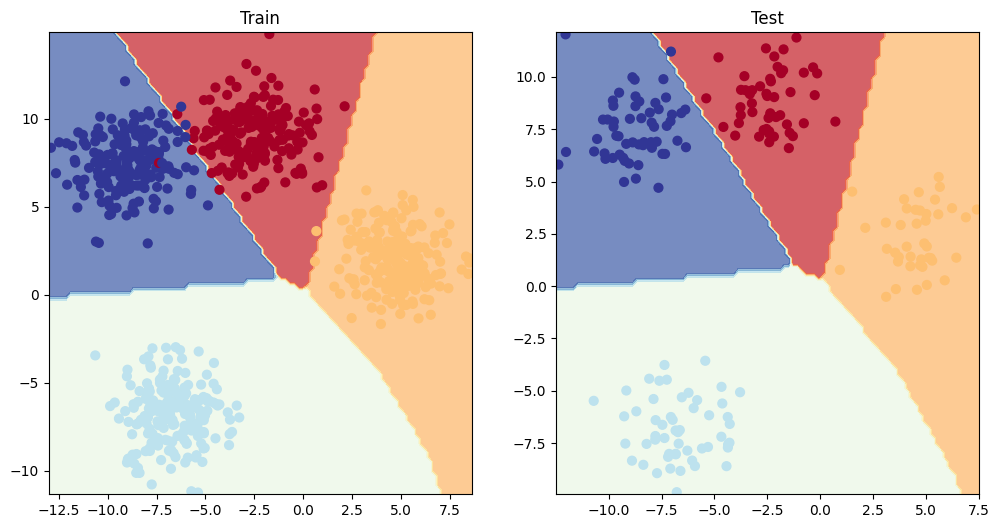

In [75]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_4, X_blob_train, y_blob_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_4, X_blob_test, y_blob_test)



### If we stoped the non-linear funs (relu) it will work, b, we can draw straight line to siparate our data

## A Few more classification matrix .... (to evalaute our classification model)

1. Accuracy - out of 100, how many does our model got right
2. Precision (good for unbalanced data)
3. Recall (good for unbalanced data)
4. F1 score
5. Confusion matrix
6. Classification report

`2 + 3` : Good for unblamced data
`trade-off` between them


If you want access to a lot of PyTorch metrics, see TorchMetrics - https://torchmetrics.readthedocs.io/en/latest/


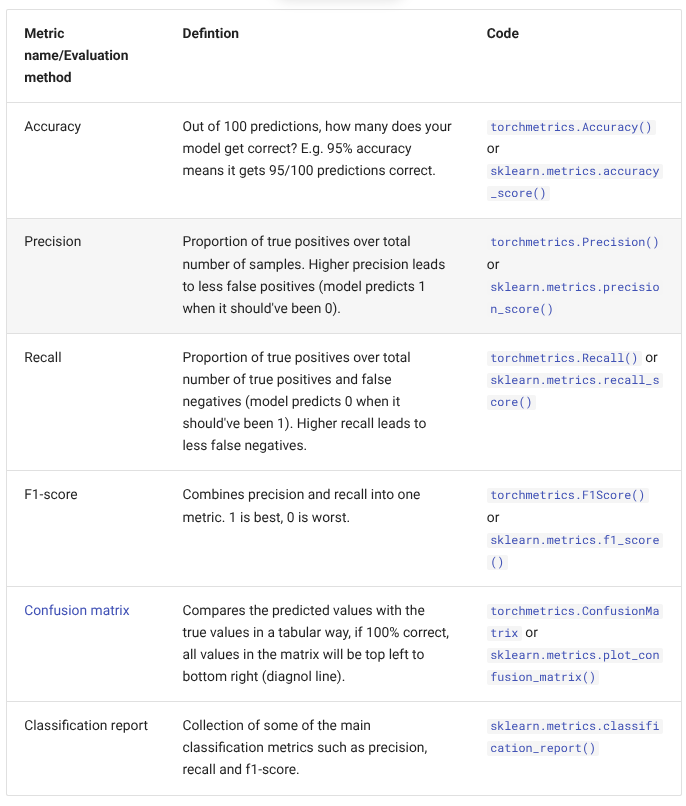


In [77]:
! pip install torchmetrics


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 20.8 MB/s eta 0:00:00


In [85]:
from torchmetrics import Accuracy

# Setup metric with the required number of classes
torchmetric_accuracy = Accuracy(task="multiclass", num_classes=NUM_CLASSES).to(device)

# Calculate accuracy
torchmetric_accuracy(y_preds, y_blob_test)

tensor(0.9950, device='cuda:0')